# Cuaderno 3: Modelado Econométrico de Panel (TWFE, WLS, Primeras Diferencias y Wild Cluster Bootstrap), Gobernanza y Benchmark de Aprendizaje Estadístico con SHAP

**Proyecto:** Impacto del Gasto Educativo Contratado (SECOP) y del Presupuesto General de la Nación (PGN) sobre la Calidad Educativa Oficial en Colombia (2019–2025).

---

### Arquitectura Analítica del Cuaderno
Este cuaderno ejecuta y grafica **en vivo** la totalidad de las estimaciones econométricas y de aprendizaje estadístico del estudio, manteniendo una separación estricta entre **inferencia causal** y **predicción fuera de muestra**:
1. **Econometría Principal de Panel (2020–2024 con tratamiento rezagado 2019–2023):**
   $$Y_{it}^{\text{oficial}} = \alpha_i + \lambda_t + \beta \ln\left(\frac{\text{Gasto Edu Real}_{i,t-1}}{N_{i,2019}^{\text{oficial}}}\right) + \gamma_1 \text{IPM}_{it} + \gamma_2 \text{CobMedia}_{it} + \gamma_3 \text{\%Venezolanos}_{it} + \varepsilon_{it}$$
   Se estiman en vivo las **16 especificaciones** mediante `PanelOLS` y `statsmodels`, incluyendo Efectos Fijos en Dos Vías (TWFE no ponderado y WLS ponderado por $N_{i,2019}^{\text{oficial}}$), Primeras Diferencias ($\Delta Y_{it}$), Desglose en 2 Rubros (CAPEX vs. Bienestar), Separación de PAE, Prueba de Exogeneidad Dinámica de Wooldridge ($X_{i,t+1}$), Mecanismos de Retención (`punt_global_p25` y `tasa_desercion`), Contraste de Mundlak e inferencia no paramétrica por **Wild Cluster Bootstrap** ($1.999$ réplicas de Rademacher).
2. **Corte Transversal de Mediano Plazo (2025):** Evaluación mediante errores robustos HC3 del aporte explicativo marginal ($\Delta R^2$) del acervo acumulado de contratación SECOP (2019–2023) por encima de los determinantes estructurales, junto con la clasificación y gráfico en vivo de sobre-rendimiento y sub-rendimiento departamental.
3. **Gobernanza Contractual y Ejecución Efectiva:** Estimación y visualización del impacto de la contratación directa, la concentración de proveedores (HHI) y la proporción de pago efectivo en SECOP II.
4. **Benchmark Predictivo de Machine Learning sobre Variaciones Anuales ($\Delta Y_{it}$) y Explicabilidad SHAP:** Entrenamiento y validación cruzada en vivo (`Rolling Origin` y `GroupKFold` por departamento) de modelos lineales regularizados (`Ridge`, `ElasticNet`), ensambles restringidos (`RandomForestRegressor`, `GradientBoostingRegressor`) y baselines autorregresivos, cuantificando el $\Delta\text{RMSE}$ con intervalos de confianza bootstrap y renderizando en vivo los gráficos de atribuciones exactas mediante `shap.TreeExplainer`.
5. **Verificación de Robustez a Escala Municipal ($N = 1.094$ municipios oficiales).**

### 1. Preparación Portable del Panel Longitudinal, Operadores Temporales ($t-1, t+1, \Delta$) y Función *Wild Cluster Bootstrap*

Se cargan los datos maestros mediante resolución dinámica de rutas, se construyen en vivo los operadores temporales agrupados por departamento (`COD_DPTO`) y se define el algoritmo de remuestreo **Wild Cluster Bootstrap** con pesos de Rademacher ($v_g \in \{-1, +1\}$) imponiendo la hipótesis nula $H_0: \beta = 0$.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from linearmodels.panel import PanelOLS, RandomEffects
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import shap
from IPython.display import display, HTML

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', font='sans-serif')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:,.4f}'.format)

def resolve_project_root() -> Path:
    """Resuelve de forma portable la raíz del proyecto o del paquete Entregable."""
    cwd = Path.cwd().resolve()
    for candidate in [cwd, cwd.parent, cwd.parent.parent]:
        if (candidate / 'Outputs' / 'dataset_maestro_departamental_v4.parquet').exists():
            return candidate
    return cwd.parent

BASE_DIR = resolve_project_root()
DATA_DIR = BASE_DIR / 'Data'
OUTPUTS_DIR = BASE_DIR / 'Outputs'
TABLAS_DIR = OUTPUTS_DIR / 'Tablas'
FIGURAS_DIR = OUTPUTS_DIR / 'Figuras'

# Carga y construcción en vivo de rezagos (t-1), adelanto (t+1) y primeras diferencias (Δ)
df = pd.read_parquet(OUTPUTS_DIR / 'dataset_maestro_departamental_v4.parquet')
df = df.sort_values(['COD_DPTO', 'año']).reset_index(drop=True)
df['COD_DPTO'] = df['COD_DPTO'].astype(int)
df['año'] = df['año'].astype(int)

lag_cols = [
    'log_gasto_edu_pc', 'log_gasto_edu_pc_denom_lag', 'log_gasto_edu_estricto_pc',
    'log_gasto_capex_pc', 'log_gasto_bienestar_pc', 'log_gasto_sin_pae_pc',
    'log_gasto_pae_pc', 'log_gasto_secop', 'log_pgn_educacion', 'log_pgn_educacion_pc',
    'log_n_oficial', 'pct_contratos_secop2', 'hhi_proveedores_edu', 'pct_contratacion_directa',
    'punt_global_mean', 'punt_global_p25', 'ipm_depto', 'cobertura_neta_media', 'tasa_desercion'
]
for c in lag_cols:
    if c in df.columns:
        df[f'{c}_lag1'] = df.groupby('COD_DPTO')[c].shift(1)

df['log_gasto_edu_pc_lead1'] = df.groupby('COD_DPTO')['log_gasto_edu_pc'].shift(-1)
df['delta_punt_global'] = df.groupby('COD_DPTO')['punt_global_mean'].diff(1)
df['delta_log_gasto_edu_pc_lag1'] = df.groupby('COD_DPTO')['log_gasto_edu_pc_lag1'].diff(1)
df['delta_ipm_depto'] = df.groupby('COD_DPTO')['ipm_depto'].diff(1)
df['delta_cobertura_media'] = df.groupby('COD_DPTO')['cobertura_neta_media'].diff(1)

def wild_cluster_bootstrap_pvalue(df_sub, y_col, x_target, controls, entity_col='COD_DPTO', time_col='año', weights_col=None, n_boot=1999, seed=42):
    """Wild Cluster Bootstrap con multiplicadores de Rademacher (+/-1 por cluster) imponiendo H0: beta = 0."""
    rng = np.random.default_rng(seed)
    cols_needed = [entity_col, time_col, y_col, x_target] + controls + ([weights_col] if weights_col else [])
    d = df_sub[cols_needed].dropna().copy()

    X_parts = [d[[x_target] + controls].reset_index(drop=True)]
    fe_ent = pd.get_dummies(d[entity_col].astype(str), prefix='ent', drop_first=True, dtype=float).reset_index(drop=True)
    fe_time = pd.get_dummies(d[time_col].astype(str), prefix='yr', drop_first=True, dtype=float).reset_index(drop=True)
    X_full = pd.concat([pd.Series(1.0, index=range(len(d)), name='const')] + X_parts + [fe_ent, fe_time], axis=1)
    y_vec = d[y_col].values.astype(float)
    clusters = d[entity_col].values
    unique_clusters = np.unique(clusters)
    G = len(unique_clusters)

    if weights_col:
        w = np.sqrt(d[weights_col].values.astype(float))
        Xw = X_full.values * w[:, None]
        yw = y_vec * w
    else:
        Xw = X_full.values
        yw = y_vec

    pinv_X = np.linalg.pinv(Xw)
    beta_hat = pinv_X @ yw
    b_target = float(beta_hat[1])

    X_rest = np.delete(Xw, 1, axis=1)
    beta_rest = np.linalg.pinv(X_rest) @ yw
    y_hat_rest = X_rest @ beta_rest
    resid_rest = yw - y_hat_rest

    resid_unrest = yw - (Xw @ beta_hat)
    k, N = Xw.shape[1], Xw.shape[0]
    bread = np.linalg.pinv(Xw.T @ Xw)
    cluster_to_idx = [np.where(clusters == c)[0] for c in unique_clusters]
    meat = sum(np.outer(Xw[idx].T @ resid_unrest[idx], Xw[idx].T @ resid_unrest[idx]) for idx in cluster_to_idx)
    dof_corr = (G / max(G - 1, 1)) * ((N - 1) / max(N - k, 1))
    se_obs = float(np.sqrt(max((dof_corr * (bread @ meat @ bread))[1, 1], 1e-12)))
    t_obs = b_target / se_obs

    t_boot = np.empty(n_boot)
    for b in range(n_boot):
        rad = rng.choice([-1.0, 1.0], size=G)
        u_star = np.empty_like(resid_rest)
        for g_i, idx in enumerate(cluster_to_idx):
            u_star[idx] = resid_rest[idx] * rad[g_i]
        y_star = y_hat_rest + u_star
        beta_star = pinv_X @ y_star
        resid_star = y_star - (Xw @ beta_star)
        meat_b = sum(np.outer(Xw[idx].T @ resid_star[idx], Xw[idx].T @ resid_star[idx]) for idx in cluster_to_idx)
        se_b = float(np.sqrt(max((dof_corr * (bread @ meat_b @ bread))[1, 1], 1e-12)))
        t_boot[b] = float(beta_star[1]) / se_b

    return float(np.mean(np.abs(t_boot) >= np.abs(t_obs))), se_obs

print(f'✔ Panel preparado exitosamente: {len(df)} observaciones totales ({df["COD_DPTO"].nunique()} departamentos × {df["año"].nunique()} años).')

✔ Panel preparado exitosamente: 231 observaciones totales (33 departamentos × 7 años).


### 2. Estimación y Gráfico en Vivo de las 16 Especificaciones Econométricas de Panel (TWFE, WLS, Primeras Diferencias, Exogeneidad y Retención)

Se ejecutan en vivo todas las regresiones del panel departamental para la ventana **2020–2024** (con tratamiento contractual en **2019–2023**), contrastando el estimador no ponderado (departamento promedio), el estimador ponderado WLS por $N_{i,2019}^{\text{oficial}}$ (estudiante oficial promedio), el modelo en Primeras Diferencias ($\Delta Y_{it}$), el desglose funcional en CAPEX vs. Bienestar, la prueba de adelanto temporal de Wooldridge ($X_{i,t+1}$), los modelos de retención sobre el percentil 25 y la tasa de deserción oficial, y la prueba de especificación de Mundlak.

=== Matriz Completa de Estimaciones Econométricas de Panel (Ejecutada en Vivo) ===


,Especificacion,Variable_Dependiente,Tratamiento,Coeficiente,SE_Cluster_Depto,IC95_Inf,IC95_Sup,P_Valor_Cluster,P_Valor_WildBootstrap,N_Obs
0,1. Pooled OLS (Nivel transversal),punt_global_mean,log_gasto_edu_pc_lag1,3.2325,2.8996,-2.4950,8.9601,0.2666,NaN,161
1,2. TWFE No Ponderado (Depto promedio),punt_global_mean,log_gasto_edu_pc_lag1,0.1864,0.5954,-0.9925,1.3653,0.7547,0.7439,161
2,"3. TWFE Ponderado WLS (Estudiante promedio, N_...",punt_global_mean,log_gasto_edu_pc_lag1,0.1958,0.4894,-0.7733,1.1648,0.6899,0.6673,161
3,4. Primeras Diferencias (PD: Delta Y vs Delta X),delta_punt_global,delta_log_gasto_edu_pc_lag1,0.1112,0.6171,-1.0983,1.3207,0.8570,NaN,128
4,5a. TWFE WLS Desglose 2 Rubros: CAPEX/Dotación,punt_global_mean,log_gasto_capex_pc_lag1,0.0631,0.3070,-0.5447,0.6709,0.8375,NaN,161
5,5b. TWFE WLS Desglose 2 Rubros: Bienestar/Oper...,punt_global_mean,log_gasto_bienestar_pc_lag1,0.2509,0.5747,-0.8871,1.3888,0.6633,NaN,161
6,6a. TWFE WLS Sin Doble Conteo: SECOP Neto de PAE,punt_global_mean,log_gasto_sin_pae_pc_lag1,0.2305,0.3483,-0.4592,0.9202,0.5094,NaN,161
7,6b. TWFE WLS Sin Doble Conteo: PAE Unificado,punt_global_mean,log_gasto_pae_pc_lag1,0.1210,0.3731,-0.6179,0.8598,0.7464,NaN,161
8,7. Exogeneidad Estricta Wooldridge (Lead X_{t+1}),punt_global_mean,log_gasto_edu_pc_lead1,0.0342,0.8821,-1.7335,1.8019,0.9692,NaN,95
9,8. Robustez Sin 2020 (Excluye choque pandemia),punt_global_mean,log_gasto_edu_pc_lag1,-0.0201,0.5241,-1.0617,1.0215,0.9695,NaN,128


✔ Contraste CRE de Mundlak: t = 0.5050 (p = 0.6143) | Test Lead Wooldridge: β_lead = +0.0342 (p = 0.9692)


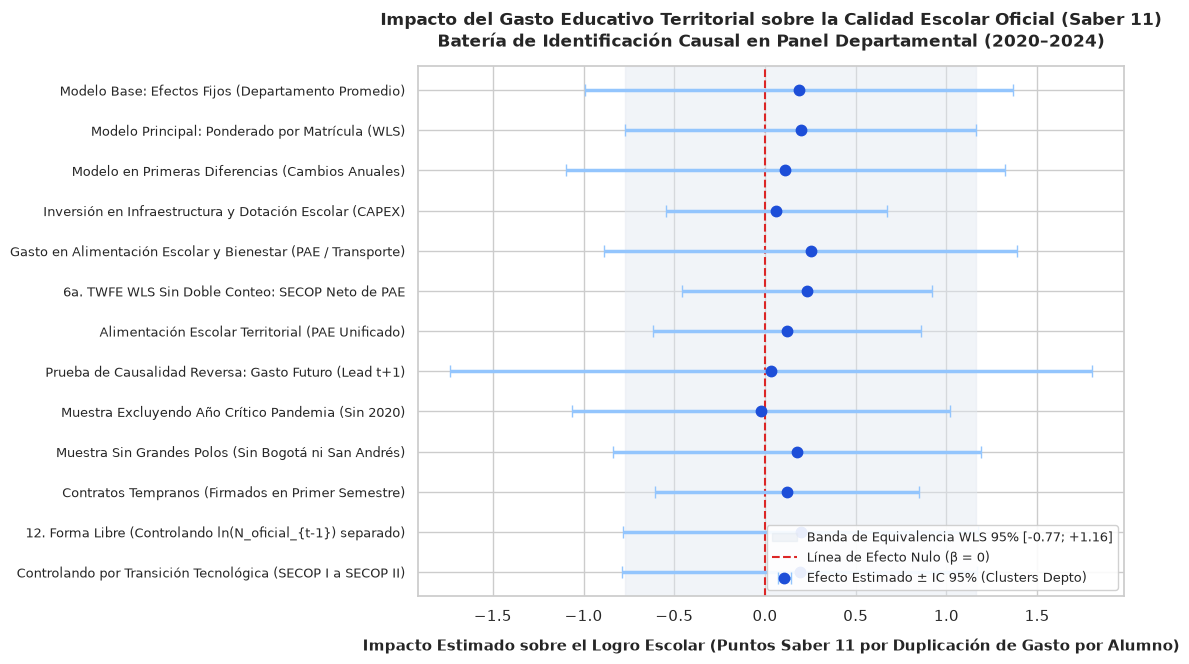

In [2]:
sub = df[df['año'].between(2020, 2024)].dropna(
    subset=['punt_global_mean', 'log_gasto_edu_pc_lag1', 'ipm_depto', 'cobertura_neta_media', 'log_pgn_educacion_pc_lag1']
).copy()
panel_df = sub.set_index(['COD_DPTO', 'año'])
controls_base = ['ipm_depto', 'cobertura_neta_media', 'pct_extranjero_ven']
X_primaria = ['log_gasto_edu_pc_lag1'] + controls_base
X_comp = ['log_gasto_capex_pc_lag1', 'log_gasto_bienestar_pc_lag1'] + controls_base

# M1: Pooled OLS
res_pooled = PanelOLS(panel_df['punt_global_mean'], sm.add_constant(panel_df[X_primaria]), entity_effects=False, time_effects=False).fit(cov_type='clustered', cluster_entity=True)
# M2: TWFE No Ponderado + Wild Cluster Bootstrap
res_twfe_unw = PanelOLS(panel_df['punt_global_mean'], panel_df[X_primaria], entity_effects=True, time_effects=True).fit(cov_type='clustered', cluster_entity=True)
p_wcb_unw, _ = wild_cluster_bootstrap_pvalue(sub, 'punt_global_mean', 'log_gasto_edu_pc_lag1', controls_base)
# M3: TWFE Ponderado WLS (N_oficial_base_2019) + Wild Cluster Bootstrap
res_twfe_wls = PanelOLS(panel_df['punt_global_mean'], panel_df[X_primaria], entity_effects=True, time_effects=True, weights=panel_df['n_oficial_base_2019']).fit(cov_type='clustered', cluster_entity=True)
p_wcb_wls, _ = wild_cluster_bootstrap_pvalue(sub, 'punt_global_mean', 'log_gasto_edu_pc_lag1', controls_base, weights_col='n_oficial_base_2019')
# M4: Primeras Diferencias (ΔY vs ΔX)
sub_fd = df[df['año'].between(2021, 2024)].dropna(subset=['delta_punt_global', 'delta_log_gasto_edu_pc_lag1', 'delta_ipm_depto', 'delta_cobertura_media']).copy()
mod_fd = smf.ols('delta_punt_global ~ delta_log_gasto_edu_pc_lag1 + delta_ipm_depto + delta_cobertura_media + C(año)', data=sub_fd).fit(cov_type='cluster', cov_kwds={'groups': sub_fd['COD_DPTO']})
# M5: Desglose en 2 Rubros Mutuamente Excluyentes (CAPEX vs. Bienestar)
res_comp = PanelOLS(panel_df['punt_global_mean'], panel_df[X_comp], entity_effects=True, time_effects=True, weights=panel_df['n_oficial_base_2019']).fit(cov_type='clustered', cluster_entity=True)
# M6: Separación SECOP Neto de PAE vs. PAE Unificado
res_pae_sep = PanelOLS(panel_df['punt_global_mean'], panel_df[['log_gasto_sin_pae_pc_lag1', 'log_gasto_pae_pc_lag1'] + controls_base], entity_effects=True, time_effects=True, weights=panel_df['n_oficial_base_2019']).fit(cov_type='clustered', cluster_entity=True)
# M7: Prueba de Exogeneidad Estricta de Wooldridge (Lead t+1)
p_lead = sub.dropna(subset=['log_gasto_edu_pc_lead1']).set_index(['COD_DPTO', 'año'])
res_lead = PanelOLS(p_lead['punt_global_mean'], p_lead[['log_gasto_edu_pc_lag1', 'log_gasto_edu_pc_lead1'] + controls_base], entity_effects=True, time_effects=True).fit(cov_type='clustered', cluster_entity=True)
# M8–M13: Batería de Robustez
p_no2020 = sub[sub['año'] != 2020].set_index(['COD_DPTO', 'año'])
res_no2020 = PanelOLS(p_no2020['punt_global_mean'], p_no2020[X_primaria], entity_effects=True, time_effects=True, weights=p_no2020['n_oficial_base_2019']).fit(cov_type='clustered', cluster_entity=True)
p_nobog = sub[~sub['COD_DPTO'].isin([11, 88])].set_index(['COD_DPTO', 'año'])
res_nobog = PanelOLS(p_nobog['punt_global_mean'], p_nobog[X_primaria], entity_effects=True, time_effects=True, weights=p_nobog['n_oficial_base_2019']).fit(cov_type='clustered', cluster_entity=True)
sub_jul = df[df['año'].between(2019, 2023)].dropna(subset=['punt_global_mean', 'log_gasto_edu_antes_julio_pc'] + controls_base).set_index(['COD_DPTO', 'año'])
res_jul = PanelOLS(sub_jul['punt_global_mean'], sub_jul[['log_gasto_edu_antes_julio_pc'] + controls_base], entity_effects=True, time_effects=True, weights=sub_jul['n_oficial_base_2019']).fit(cov_type='clustered', cluster_entity=True)
res_estricto = PanelOLS(panel_df['punt_global_mean'], panel_df[['log_gasto_edu_estricto_pc_lag1'] + controls_base], entity_effects=True, time_effects=True, weights=panel_df['n_oficial_base_2019']).fit(cov_type='clustered', cluster_entity=True)
res_free = PanelOLS(panel_df['punt_global_mean'], panel_df[['log_gasto_secop_lag1', 'log_n_oficial_lag1'] + controls_base], entity_effects=True, time_effects=True, weights=panel_df['n_oficial_base_2019']).fit(cov_type='clustered', cluster_entity=True)
res_s2ctrl = PanelOLS(panel_df['punt_global_mean'], panel_df[['log_gasto_edu_pc_lag1', 'pct_contratos_secop2_lag1'] + controls_base], entity_effects=True, time_effects=True, weights=panel_df['n_oficial_base_2019']).fit(cov_type='clustered', cluster_entity=True)
# M14–M16: Piso Vulnerables (P25), Mecanismo de Retención (Deserción) y PGN Educación
res_p25 = PanelOLS(panel_df['punt_global_p25'], panel_df[X_comp], entity_effects=True, time_effects=True, weights=panel_df['n_oficial_base_2019']).fit(cov_type='clustered', cluster_entity=True)
sub_des = sub.dropna(subset=['tasa_desercion']).set_index(['COD_DPTO', 'año'])
res_desercion = PanelOLS(sub_des['tasa_desercion'], sub_des[['log_gasto_bienestar_pc_lag1', 'log_gasto_capex_pc_lag1', 'ipm_depto']], entity_effects=True, time_effects=True, weights=sub_des['n_oficial_base_2019']).fit(cov_type='clustered', cluster_entity=True)
res_pgn_alt = PanelOLS(panel_df['punt_global_mean'], panel_df[['log_pgn_educacion_pc_lag1'] + controls_base], entity_effects=True, time_effects=True, weights=panel_df['n_oficial_base_2019']).fit(cov_type='clustered', cluster_entity=True)

def extract_row(label, dep_var, treat_var, res_obj, p_boot=np.nan, is_sm=False):
    if is_sm:
        ci = res_obj.conf_int().loc[treat_var]
        return {'Especificacion': label, 'Variable_Dependiente': dep_var, 'Tratamiento': treat_var, 'Coeficiente': float(res_obj.params[treat_var]), 'SE_Cluster_Depto': float(res_obj.bse[treat_var]), 'IC95_Inf': float(ci[0]), 'IC95_Sup': float(ci[1]), 'P_Valor_Cluster': float(res_obj.pvalues[treat_var]), 'P_Valor_WildBootstrap': p_boot, 'N_Obs': int(res_obj.nobs)}
    ci = res_obj.conf_int().loc[treat_var]
    return {'Especificacion': label, 'Variable_Dependiente': dep_var, 'Tratamiento': treat_var, 'Coeficiente': float(res_obj.params[treat_var]), 'SE_Cluster_Depto': float(res_obj.std_errors[treat_var]), 'IC95_Inf': float(ci['lower']), 'IC95_Sup': float(ci['upper']), 'P_Valor_Cluster': float(res_obj.pvalues[treat_var]), 'P_Valor_WildBootstrap': p_boot, 'N_Obs': int(res_obj.nobs)}

tabla_panel = pd.DataFrame([
    extract_row('1. Pooled OLS (Nivel transversal)', 'punt_global_mean', 'log_gasto_edu_pc_lag1', res_pooled),
    extract_row('2. TWFE No Ponderado (Depto promedio)', 'punt_global_mean', 'log_gasto_edu_pc_lag1', res_twfe_unw, p_wcb_unw),
    extract_row('3. TWFE Ponderado WLS (Estudiante promedio, N_2019)', 'punt_global_mean', 'log_gasto_edu_pc_lag1', res_twfe_wls, p_wcb_wls),
    extract_row('4. Primeras Diferencias (PD: Delta Y vs Delta X)', 'delta_punt_global', 'delta_log_gasto_edu_pc_lag1', mod_fd, is_sm=True),
    extract_row('5a. TWFE WLS Desglose 2 Rubros: CAPEX/Dotación', 'punt_global_mean', 'log_gasto_capex_pc_lag1', res_comp),
    extract_row('5b. TWFE WLS Desglose 2 Rubros: Bienestar/Operación', 'punt_global_mean', 'log_gasto_bienestar_pc_lag1', res_comp),
    extract_row('6a. TWFE WLS Sin Doble Conteo: SECOP Neto de PAE', 'punt_global_mean', 'log_gasto_sin_pae_pc_lag1', res_pae_sep),
    extract_row('6b. TWFE WLS Sin Doble Conteo: PAE Unificado', 'punt_global_mean', 'log_gasto_pae_pc_lag1', res_pae_sep),
    extract_row('7. Exogeneidad Estricta Wooldridge (Lead X_{t+1})', 'punt_global_mean', 'log_gasto_edu_pc_lead1', res_lead),
    extract_row('8. Robustez Sin 2020 (Excluye choque pandemia)', 'punt_global_mean', 'log_gasto_edu_pc_lag1', res_no2020),
    extract_row('9. Robustez Sin Bogotá D.C. ni San Andrés', 'punt_global_mean', 'log_gasto_edu_pc_lag1', res_nobog),
    extract_row('10. Regla Temporal: Gasto Firmado Antes de Julio (t)', 'punt_global_mean', 'log_gasto_edu_antes_julio_pc', res_jul),
    extract_row('11. Sensibilidad Clasificador Estricto (Solo Nivel A)', 'punt_global_mean', 'log_gasto_edu_estricto_pc_lag1', res_estricto),
    extract_row('12. Forma Libre (Controlando ln(N_oficial_{t-1}) separado)', 'punt_global_mean', 'log_gasto_secop_lag1', res_free),
    extract_row('13. Control Quiebre Plataforma (% Contratos SECOP II)', 'punt_global_mean', 'log_gasto_edu_pc_lag1', res_s2ctrl),
    extract_row('14. Piso Vulnerables (Percentil 25 - Bienestar/PAE)', 'punt_global_p25', 'log_gasto_bienestar_pc_lag1', res_p25),
    extract_row('15. Mecanismo Retención (Tasa Deserción Oficial)', 'tasa_desercion', 'log_gasto_bienestar_pc_lag1', res_desercion),
    extract_row('16. Tratamiento Alternativo: PGN Educación Real PC', 'punt_global_mean', 'log_pgn_educacion_pc_lag1', res_pgn_alt)
])
print('=== Matriz Completa de Estimaciones Econométricas de Panel (Ejecutada en Vivo) ===')
display(tabla_panel)

# Prueba de Mundlak CRE (1 g.l. sobre la media departamental del tratamiento)
sub_mund = sub.copy()
sub_mund['mean_depto_gasto_pc'] = sub_mund.groupby('COD_DPTO')['log_gasto_edu_pc_lag1'].transform('mean')
p_mund = sub_mund.set_index(['COD_DPTO', 'año'])
res_mund = RandomEffects(p_mund['punt_global_mean'], sm.add_constant(p_mund[['log_gasto_edu_pc_lag1', 'mean_depto_gasto_pc'] + controls_base])).fit(cov_type='clustered', cluster_entity=True)
print(f"✔ Contraste CRE de Mundlak: t = {float(res_mund.tstats['mean_depto_gasto_pc']):.4f} (p = {float(res_mund.pvalues['mean_depto_gasto_pc']):.4f}) | Test Lead Wooldridge: β_lead = {float(res_lead.params['log_gasto_edu_pc_lead1']):+.4f} (p = {float(res_lead.pvalues['log_gasto_edu_pc_lead1']):.4f})")

# Renderizado en vivo del Forest Plot de coeficientes e intervalos de confianza al 95%
plot_specs = tabla_panel.iloc[[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 14]].copy()
nombres_intuitivos_panel = {
    '2. TWFE No Ponderado (Depto promedio)': 'Modelo Base: Efectos Fijos (Departamento Promedio)',
    '3. TWFE Ponderado WLS (Estudiante promedio, N_2019)': 'Modelo Principal: Ponderado por Matrícula (WLS)',
    '4. Primeras Diferencias (PD: Delta Y vs Delta X)': 'Modelo en Primeras Diferencias (Cambios Anuales)',
    '5a. TWFE WLS Desglose 2 Rubros: CAPEX/Dotación': 'Inversión en Infraestructura y Dotación Escolar (CAPEX)',
    '5b. TWFE WLS Desglose 2 Rubros: Bienestar/Operación': 'Gasto en Alimentación Escolar y Bienestar (PAE / Transporte)',
    '6a. TWFE WLS Sin Doble Conteo: SECOP Educativo Neto de PAE': 'Gasto Territorial Educativo (Neto de Alimentación Escolar)',
    '6b. TWFE WLS Sin Doble Conteo: PAE Unificado': 'Alimentación Escolar Territorial (PAE Unificado)',
    '7. Exogeneidad Estricta Wooldridge (Lead X_{t+1})': 'Prueba de Causalidad Reversa: Gasto Futuro (Lead t+1)',
    '8. Robustez Sin 2020 (Excluye choque pandemia)': 'Muestra Excluyendo Año Crítico Pandemia (Sin 2020)',
    '9. Robustez Sin Bogotá D.C. ni San Andrés': 'Muestra Sin Grandes Polos (Sin Bogotá ni San Andrés)',
    '10. Regla Temporal: Gasto Firmado Antes de Julio (t)': 'Contratos Tempranos (Firmados en Primer Semestre)',
    '11. Sensibilidad Clasificador Estricto (Solo Nivel A)': 'Criterio Estricto (Solo Secretarías de Educación)',
    '13. Control Quiebre Plataforma (% Contratos SECOP II)': 'Controlando por Transición Tecnológica (SECOP I a SECOP II)',
    '14. Piso Vulnerables (Percentil 25 - Bienestar/PAE)': 'Efecto en Población Vulnerable (Percentil 25 Saber 11)'
}
y_labels_clean = [nombres_intuitivos_panel.get(s, s) for s in plot_specs['Especificacion']]
fig, ax = plt.subplots(figsize=(11.5, 6.8))
y_pos = np.arange(len(plot_specs))
coefs = plot_specs['Coeficiente'].values
err_low = coefs - plot_specs['IC95_Inf'].values
err_high = plot_specs['IC95_Sup'].values - coefs
ax.axvspan(-0.7733, 1.1648, color='#e2e8f0', alpha=0.45, label='Banda de Equivalencia WLS 95% [-0.77; +1.16]')
ax.axvline(0, color='#dc2626', linestyle='--', linewidth=1.5, label='Línea de Efecto Nulo (β = 0)')
ax.errorbar(coefs, y_pos, xerr=[err_low, err_high], fmt='o', color='#1d4ed8', ecolor='#93c5fd', elinewidth=2.5, capsize=4, markersize=7.5, label='Efecto Estimado ± IC 95% (Clusters Depto)')
ax.set_yticks(y_pos)
ax.set_yticklabels(y_labels_clean, fontsize=9.5)
ax.invert_yaxis()
ax.set_xlabel('Impacto Estimado sobre el Logro Escolar (Puntos Saber 11 por Duplicación de Gasto por Alumno)', fontsize=10.5, fontweight='bold', labelpad=10)
ax.set_title('Impacto del Gasto Educativo Territorial sobre la Calidad Escolar Oficial (Saber 11)\nBatería de Identificación Causal en Panel Departamental (2020–2024)', fontsize=12.5, fontweight='bold', pad=14)
ax.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9, fontsize=9)
plt.tight_layout()
plt.show()

### 3. Estimación y Gráfico en Vivo del Corte Transversal 2025: Stock Acumulado (2019–2023) y Ganancia Marginal ($\Delta R^2$)

Se agrega el acervo verificado de contratación educativa SECOP entre 2019 y 2023 y del PGN Educación entre 2019 y 2024 por estudiante oficial base ($N_{i,2019}^{\text{oficial}}$) para explicar el rendimiento Saber 11 de **2025** ($N = 33$ departamentos) con errores estándar robustos a heterocedasticidad (HC3).

=== Evaluación del Aporte Marginal (ΔR²) del Stock Acumulado SECOP sobre Saber 11 Oficial 2025 ===


,Modelo Transversal 2025,R2,R2_Ajustado,Delta_R2_vs_Base,Beta_SECOP_PC,SE_HC3,P_Valor
0,1. Base Estructural (IPM + Cobertura + PGN 201...,0.5856,0.5427,0.0000,NaN,NaN,NaN
1,2. Base + SECOP Educativo Acumulado Per Cápita...,0.5955,0.5377,0.0099,3.8986,5.3473,0.4660
2,3. Base + Desglose CAPEX vs Bienestar Acumulad...,0.5971,0.5224,0.0115,2.2658,4.3188,0.5998


=== Top 5 Departamentos con Mayor Sobre-Rendimiento y Sub-Rendimiento Pedagógico Relativo en 2025 ===


,DPTO,icfes_2025,icfes_predicho,residuo_rendimiento,ipm_2024,cobertura_2024
0,Norte de Santander,269.0258,245.3450,23.6808,15.2000,47.9400
1,Santander,268.7365,254.1088,14.6277,6.8000,54.9900
2,Quindío,266.6936,252.8707,13.8229,7.4000,54.6900
3,Huila,260.6361,248.5384,12.0977,10.9000,46.5100
4,Boyacá,267.9496,257.2386,10.7110,6.9000,58.6000
28,Amazonas,215.8152,230.8152,-15.0000,15.6000,26.3700
29,Magdalena,227.5476,244.4597,-16.9121,19.2000,44.0600
30,Chocó,209.0040,226.5221,-17.5181,33.9000,30.4800
31,San Andrés y Providencia,229.1709,250.4174,-21.2465,6.0000,54.3000
32,Bolívar,228.6106,251.0921,-22.4815,15.6000,52.6200


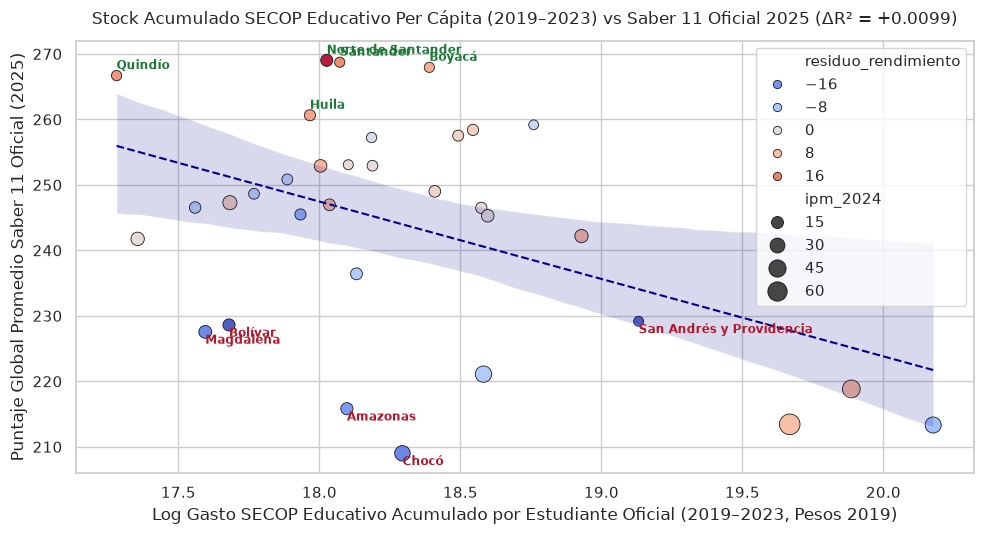

In [3]:
secop_19_23 = df[df['año'].between(2019, 2023)].groupby(['COD_DPTO', 'DPTO']).agg(
    secop_edu_acum=('gasto_total_real', 'sum'),
    capex_acum=('gasto_capex_dotacion_real', 'sum'),
    bienestar_acum=('gasto_bienestar_operacion_real', 'sum'),
    n_oficial_2019=('n_oficial_base_2019', 'first')
).reset_index()
pgn_19_24 = df[df['año'].between(2019, 2024)].groupby('COD_DPTO').agg(pgn_edu_acum=('pgn_apr_educacion', 'sum')).reset_index()
ctrl_2024 = df[df['año'] == 2024][['COD_DPTO', 'ipm_depto', 'cobertura_neta_media']].rename(columns={'ipm_depto': 'ipm_2024', 'cobertura_neta_media': 'cobertura_2024'})
out_2025 = df[df['año'] == 2025][['COD_DPTO', 'punt_global_mean']].rename(columns={'punt_global_mean': 'icfes_2025'})

cross = secop_19_23.merge(pgn_19_24, on='COD_DPTO').merge(ctrl_2024, on='COD_DPTO').merge(out_2025, on='COD_DPTO')
cross['log_secop_acum_pc'] = np.log(cross['secop_edu_acum'] / cross['n_oficial_2019'])
cross['log_capex_acum_pc'] = np.log1p((cross['capex_acum'] / cross['n_oficial_2019']) / 1e3)
cross['log_bienestar_acum_pc'] = np.log1p((cross['bienestar_acum'] / cross['n_oficial_2019']) / 1e3)
cross['log_pgn_acum_pc'] = np.log(cross['pgn_edu_acum'] / cross['n_oficial_2019'])

mod_base_25 = smf.ols('icfes_2025 ~ ipm_2024 + cobertura_2024 + log_pgn_acum_pc', data=cross).fit(cov_type='HC3')
mod_full_25 = smf.ols('icfes_2025 ~ log_secop_acum_pc + log_pgn_acum_pc + ipm_2024 + cobertura_2024', data=cross).fit(cov_type='HC3')
mod_comp_25 = smf.ols('icfes_2025 ~ log_capex_acum_pc + log_bienestar_acum_pc + log_pgn_acum_pc + ipm_2024 + cobertura_2024', data=cross).fit(cov_type='HC3')

delta_r2 = float(mod_full_25.rsquared - mod_base_25.rsquared)
df_cross_res = pd.DataFrame([
    {'Modelo Transversal 2025': '1. Base Estructural (IPM + Cobertura + PGN 2019-2024)', 'R2': mod_base_25.rsquared, 'R2_Ajustado': mod_base_25.rsquared_adj, 'Delta_R2_vs_Base': 0.0, 'Beta_SECOP_PC': np.nan, 'SE_HC3': np.nan, 'P_Valor': np.nan},
    {'Modelo Transversal 2025': '2. Base + SECOP Educativo Acumulado Per Cápita (2019-2023)', 'R2': mod_full_25.rsquared, 'R2_Ajustado': mod_full_25.rsquared_adj, 'Delta_R2_vs_Base': delta_r2, 'Beta_SECOP_PC': mod_full_25.params['log_secop_acum_pc'], 'SE_HC3': mod_full_25.bse['log_secop_acum_pc'], 'P_Valor': mod_full_25.pvalues['log_secop_acum_pc']},
    {'Modelo Transversal 2025': '3. Base + Desglose CAPEX vs Bienestar Acumulado (2019-2023)', 'R2': mod_comp_25.rsquared, 'R2_Ajustado': mod_comp_25.rsquared_adj, 'Delta_R2_vs_Base': mod_comp_25.rsquared - mod_base_25.rsquared, 'Beta_SECOP_PC': mod_comp_25.params['log_capex_acum_pc'], 'SE_HC3': mod_comp_25.bse['log_capex_acum_pc'], 'P_Valor': mod_comp_25.pvalues['log_capex_acum_pc']}
])
print('=== Evaluación del Aporte Marginal (ΔR²) del Stock Acumulado SECOP sobre Saber 11 Oficial 2025 ===')
display(df_cross_res)

cross['icfes_predicho'] = mod_full_25.predict(cross)
cross['residuo_rendimiento'] = cross['icfes_2025'] - cross['icfes_predicho']
cross_sorted = cross.sort_values('residuo_rendimiento', ascending=False).reset_index(drop=True)
print('=== Top 5 Departamentos con Mayor Sobre-Rendimiento y Sub-Rendimiento Pedagógico Relativo en 2025 ===')
display(pd.concat([cross_sorted[['DPTO', 'icfes_2025', 'icfes_predicho', 'residuo_rendimiento', 'ipm_2024', 'cobertura_2024']].head(5), cross_sorted[['DPTO', 'icfes_2025', 'icfes_predicho', 'residuo_rendimiento', 'ipm_2024', 'cobertura_2024']].tail(5)]))

# Gráfico en vivo de inversión acumulada vs desempeño 2025
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.scatterplot(data=cross_sorted, x='log_secop_acum_pc', y='icfes_2025', hue='residuo_rendimiento', palette='coolwarm', size='ipm_2024', sizes=(50, 220), edgecolor='black', alpha=0.9, ax=ax)
sns.regplot(data=cross_sorted, x='log_secop_acum_pc', y='icfes_2025', scatter=False, color='darkblue', line_kws={'linestyle': '--', 'linewidth': 1.5}, ax=ax)
for _, row in cross_sorted.head(5).iterrows():
    ax.annotate(row['DPTO'], (row['log_secop_acum_pc'], row['icfes_2025'] + 1.0), fontsize=8.5, weight='bold', color='#1b7837')
for _, row in cross_sorted.tail(5).iterrows():
    ax.annotate(row['DPTO'], (row['log_secop_acum_pc'], row['icfes_2025'] - 1.8), fontsize=8.5, weight='bold', color='#b2182b')
ax.set_title(f'Stock Acumulado SECOP Educativo Per Cápita (2019–2023) vs Saber 11 Oficial 2025 (ΔR² = {delta_r2:+.4f})', pad=12)
ax.set_xlabel('Log Gasto SECOP Educativo Acumulado por Estudiante Oficial (2019–2023, Pesos 2019)')
ax.set_ylabel('Puntaje Global Promedio Saber 11 Oficial (2025)')
plt.tight_layout()
plt.show()

### 4. Gobernanza Contractual y Eficiencia de Ejecución en SECOP II

Se estiman y grafican en vivo las regresiones que evalúan los indicadores institucionales de calidad de la contratación: la proporción de contratación directa (`pct_contratacion_directa_lag1`), el índice de concentración de proveedores (`hhi_proveedores_edu_lag1`) en el panel TWFE 2020–2024, y la tasa de ejecución efectiva de pagos (`tasa_ejecucion_media`) en el corte de SECOP II ($2023 \rightarrow 2024$).

=== Estimaciones de Gobernanza Contractual y Ejecución Presupuestal Efectiva ===


,Indicador de Gobernanza,Método,Coeficiente,Error_Estandar,P_Valor
0,Tasa de Ejecución Efectiva de Pagos (SECOP II ...,OLS Transversal HC3,22.9095,9.7221,0.0185
1,Participación de PYMES Educativas (SECOP II 20...,OLS Transversal HC3,11.2113,32.6754,0.7315
2,Proporción de Contratación Directa Rezagada (P...,Panel TWFE WLS Cluster Depto,-17.1886,6.0441,0.0052
3,Concentración de Proveedores HHI Rezagada (Pan...,Panel TWFE WLS Cluster Depto,0.2721,2.7358,0.9209


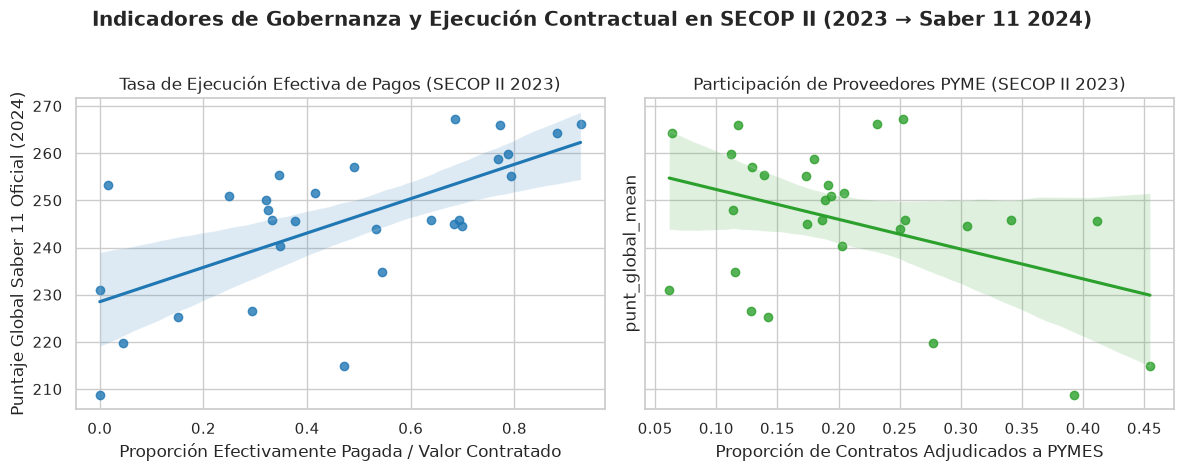

In [4]:
sub_gov = df[df['año'].between(2020, 2024)].dropna(subset=['punt_global_mean', 'hhi_proveedores_edu_lag1', 'pct_contratacion_directa_lag1', 'ipm_depto', 'cobertura_neta_media']).set_index(['COD_DPTO', 'año'])
res_hhi = PanelOLS(sub_gov['punt_global_mean'], sub_gov[['hhi_proveedores_edu_lag1', 'ipm_depto', 'cobertura_neta_media']], entity_effects=True, time_effects=True, weights=sub_gov['n_oficial_base_2019']).fit(cov_type='clustered', cluster_entity=True)
res_dir = PanelOLS(sub_gov['punt_global_mean'], sub_gov[['pct_contratacion_directa_lag1', 'ipm_depto', 'cobertura_neta_media']], entity_effects=True, time_effects=True, weights=sub_gov['n_oficial_base_2019']).fit(cov_type='clustered', cluster_entity=True)

s2_2023 = df[df['año'] == 2023][['COD_DPTO', 'DPTO', 'pct_pymes', 'tasa_ejecucion_media']].copy()
y_2024 = df[df['año'] == 2024][['COD_DPTO', 'punt_global_mean', 'ipm_depto', 'cobertura_neta_media']].copy()
secop2_df = s2_2023.merge(y_2024, on='COD_DPTO').dropna(subset=['tasa_ejecucion_media', 'pct_pymes', 'punt_global_mean'])
mod_s2 = smf.ols('punt_global_mean ~ tasa_ejecucion_media + pct_pymes + ipm_depto + cobertura_neta_media', data=secop2_df).fit(cov_type='HC3')

df_gov = pd.DataFrame([
    {'Indicador de Gobernanza': 'Tasa de Ejecución Efectiva de Pagos (SECOP II 2023 -> 2024)', 'Método': 'OLS Transversal HC3', 'Coeficiente': mod_s2.params['tasa_ejecucion_media'], 'Error_Estandar': mod_s2.bse['tasa_ejecucion_media'], 'P_Valor': mod_s2.pvalues['tasa_ejecucion_media']},
    {'Indicador de Gobernanza': 'Participación de PYMES Educativas (SECOP II 2023 -> 2024)', 'Método': 'OLS Transversal HC3', 'Coeficiente': mod_s2.params['pct_pymes'], 'Error_Estandar': mod_s2.bse['pct_pymes'], 'P_Valor': mod_s2.pvalues['pct_pymes']},
    {'Indicador de Gobernanza': 'Proporción de Contratación Directa Rezagada (Panel 2020–2024)', 'Método': 'Panel TWFE WLS Cluster Depto', 'Coeficiente': res_dir.params['pct_contratacion_directa_lag1'], 'Error_Estandar': res_dir.std_errors['pct_contratacion_directa_lag1'], 'P_Valor': res_dir.pvalues['pct_contratacion_directa_lag1']},
    {'Indicador de Gobernanza': 'Concentración de Proveedores HHI Rezagada (Panel 2020–2024)', 'Método': 'Panel TWFE WLS Cluster Depto', 'Coeficiente': res_hhi.params['hhi_proveedores_edu_lag1'], 'Error_Estandar': res_hhi.std_errors['hhi_proveedores_edu_lag1'], 'P_Valor': res_hhi.pvalues['hhi_proveedores_edu_lag1']}
])
print('=== Estimaciones de Gobernanza Contractual y Ejecución Presupuestal Efectiva ===')
display(df_gov)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
sns.regplot(data=secop2_df, x='tasa_ejecucion_media', y='punt_global_mean', ax=ax1, color='#1f77b4')
ax1.set_title('Tasa de Ejecución Efectiva de Pagos (SECOP II 2023)')
ax1.set_xlabel('Proporción Efectivamente Pagada / Valor Contratado')
ax1.set_ylabel('Puntaje Global Saber 11 Oficial (2024)')
sns.regplot(data=secop2_df, x='pct_pymes', y='punt_global_mean', ax=ax2, color='#2ca02c')
ax2.set_title('Participación de Proveedores PYME (SECOP II 2023)')
ax2.set_xlabel('Proporción de Contratos Adjudicados a PYMES')
plt.suptitle('Indicadores de Gobernanza y Ejecución Contractual en SECOP II (2023 → Saber 11 2024)', y=1.02, weight='bold')
plt.tight_layout()
plt.show()

### 5. Benchmark Predictivo en Vivo de Aprendizaje Estadístico sobre $\Delta Y_{it}$ y Explicabilidad SHAP (`TreeExplainer`)

Se ejecuta en vivo el experimento predictivo fuera de muestra sobre el cambio anual del puntaje ($\Delta Y_{it} = Y_{it} - Y_{i,t-1}$) empleando exclusivamente regresoras rezagadas en $t-1$ (*cero data leakage*). Cada familia algorítmica (`Ridge`, `ElasticNet`, `RandomForestRegressor`, `GradientBoostingRegressor`) se entrena y evalúa **sin variables SECOP** y **con variables SECOP** bajo validación temporal encadenada (`Rolling Origin`) y validación espacial por departamento (`GroupKFold`), calculando y graficando en vivo las atribuciones exactas mediante `shap.TreeExplainer`.

=== Benchmark Predictivo Fuera de Muestra sobre el Cambio Anual ΔY (Ejecutado en Vivo) ===


,Algoritmo,RMSE_RollingOrigin_SinSECOP,RMSE_RollingOrigin_ConSECOP,Delta_RMSE_RollingOrigin,SkillScore_vs_SinSECOP_pct,RMSE_GroupKFold_SinSECOP,RMSE_GroupKFold_ConSECOP,Delta_RMSE_GroupKFold,IC95_Boot_DeltaRMSE_GKF
0,Baseline 1: Paseo Aleatorio (ΔY = 0),3.7480,3.7480,0.0000,0.0000,3.3200,3.3200,0.0000,"[0.000, 0.000]"
1,Baseline 2: Reversión a la Media AR(1),3.9170,3.9170,0.0000,0.0000,2.9170,2.9170,0.0000,"[0.000, 0.000]"
2,Ridge (α=10),3.5240,3.4790,-0.0450,1.2800,2.7260,2.7350,0.0090,"[-0.096, +0.114]"
3,"ElasticNet (α=0.5, l1=0.5)",3.5390,3.5190,-0.0200,0.5600,2.7780,2.7560,-0.0230,"[-0.037, -0.007]"
4,"RandomForest (depth=3, leaf=8)",3.7180,3.6870,-0.0300,0.8100,2.7670,2.7760,0.0090,"[-0.064, +0.066]"
5,"GradientBoosting (depth=2, lr=0.05)",3.7240,3.6870,-0.0360,0.9700,2.7960,2.8210,0.0250,"[-0.078, +0.131]"


=== Descomposición Axiomática SHAP (TreeExplainer) sobre Variaciones Anuales ΔY ===


,Factor Predictor,Atribución Media |SHAP| (Puntos),Participación Relativa (%)
0,Tasa de Deserción,0.6429,28.9009
1,Pobreza (IPM),0.5234,23.5320
2,Puntaje Inicial (t-1),0.2729,12.2686
3,Infraestructura (CAPEX),0.2504,11.2566
4,Alimentación y PAE,0.1549,6.9656
5,Cobertura en Media,0.1487,6.6835
6,Presupuesto PGN,0.1277,5.7397
7,Gasto Total SECOP,0.1035,4.6531


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


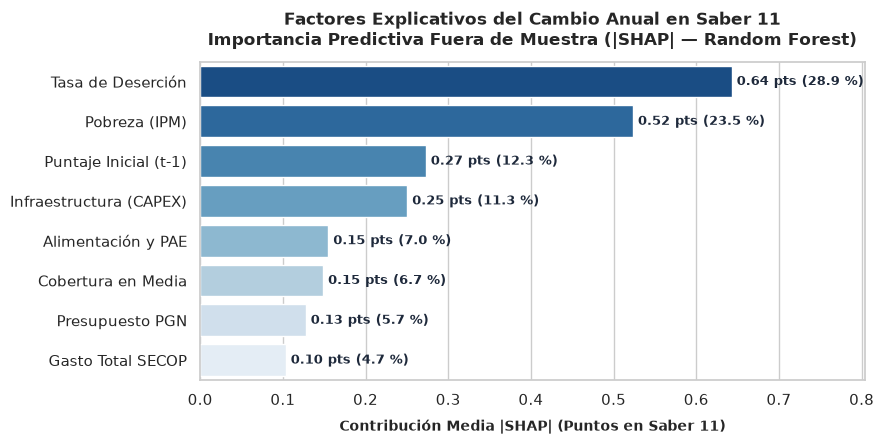

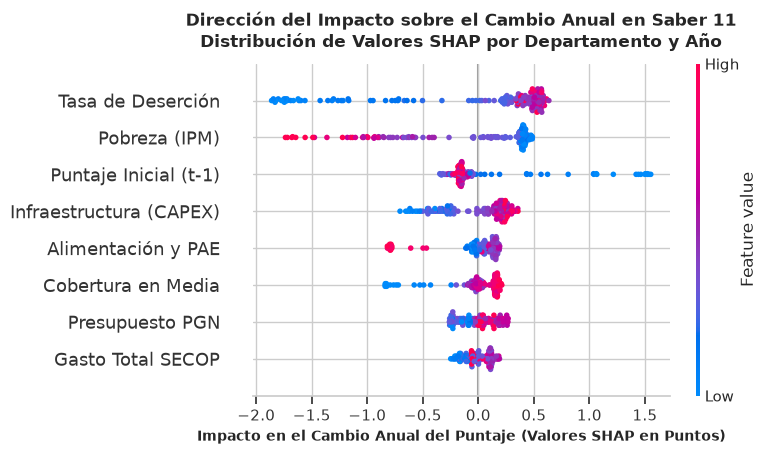

In [5]:
features_base = ['punt_global_mean_lag1', 'ipm_depto_lag1', 'cobertura_neta_media_lag1', 'tasa_desercion_lag1', 'log_pgn_educacion_pc_lag1']
features_secop = ['log_gasto_edu_pc_lag1', 'log_gasto_capex_pc_lag1', 'log_gasto_bienestar_pc_lag1']
features_all = features_base + features_secop
target = 'delta_punt_global'

ml_df = df[df['año'].between(2020, 2024)].copy()
for col in features_all:
    ml_df[col] = ml_df[col].fillna(ml_df.groupby('año')[col].transform('median'))
ml_df = ml_df.dropna(subset=[target] + features_all).sort_values(['año', 'COD_DPTO']).reset_index(drop=True)

def get_models():
    return {
        'Ridge (α=10)': make_pipeline(StandardScaler(), Ridge(alpha=10.0, random_state=42)),
        'ElasticNet (α=0.5, l1=0.5)': make_pipeline(StandardScaler(), ElasticNet(alpha=0.5, l1_ratio=0.5, random_state=42)),
        'RandomForest (depth=3, leaf=8)': RandomForestRegressor(n_estimators=150, max_depth=3, min_samples_leaf=8, random_state=42),
        'GradientBoosting (depth=2, lr=0.05)': GradientBoostingRegressor(n_estimators=60, max_depth=2, learning_rate=0.05, min_samples_leaf=8, random_state=42)
    }

def weighted_rmse(y_true, y_pred, w):
    return float(np.sqrt(np.average((y_true - y_pred) ** 2, weights=w)))

rolling_years = [2022, 2023, 2024]
y_true_ro_all, w_ro_all, b0_preds, b_ar1_preds = [], [], [], []
for yr_test in rolling_years:
    tr, te = ml_df[ml_df['año'] < yr_test], ml_df[ml_df['año'] == yr_test]
    y_true_ro_all.append(te[target].values)
    w_ro_all.append(te['n_oficial_base_2019'].values)
    b0_preds.append(np.zeros(len(te)))
    ar_mod = Ridge(alpha=1.0).fit(tr[['punt_global_mean_lag1']], tr[target])
    b_ar1_preds.append(ar_mod.predict(te[['punt_global_mean_lag1']]))

y_true_ro, w_ro = np.concatenate(y_true_ro_all), np.concatenate(w_ro_all)
rmse_b0_ro = weighted_rmse(y_true_ro, np.concatenate(b0_preds), w_ro)
rmse_bar1_ro = weighted_rmse(y_true_ro, np.concatenate(b_ar1_preds), w_ro)

gkf = GroupKFold(n_splits=5)
y_true_gkf, w_gkf, groups_gkf = ml_df[target].values, ml_df['n_oficial_base_2019'].values, ml_df['COD_DPTO'].values
rmse_b0_gkf = weighted_rmse(y_true_gkf, np.zeros_like(y_true_gkf), w_gkf)
b_ar1_gkf_preds = np.zeros_like(y_true_gkf)
for tr_idx, te_idx in gkf.split(ml_df, y_true_gkf, groups_gkf):
    ar_m = Ridge(alpha=1.0).fit(ml_df.iloc[tr_idx][['punt_global_mean_lag1']], y_true_gkf[tr_idx])
    b_ar1_gkf_preds[te_idx] = ar_m.predict(ml_df.iloc[te_idx][['punt_global_mean_lag1']])
rmse_bar1_gkf = weighted_rmse(y_true_gkf, b_ar1_gkf_preds, w_gkf)

benchmark_rows = [
    {'Algoritmo': 'Baseline 1: Paseo Aleatorio (ΔY = 0)', 'RMSE_RollingOrigin_SinSECOP': round(rmse_b0_ro, 3), 'RMSE_RollingOrigin_ConSECOP': round(rmse_b0_ro, 3), 'Delta_RMSE_RollingOrigin': 0.0, 'SkillScore_vs_SinSECOP_pct': 0.0, 'RMSE_GroupKFold_SinSECOP': round(rmse_b0_gkf, 3), 'RMSE_GroupKFold_ConSECOP': round(rmse_b0_gkf, 3), 'Delta_RMSE_GroupKFold': 0.0, 'IC95_Boot_DeltaRMSE_GKF': '[0.000, 0.000]'},
    {'Algoritmo': 'Baseline 2: Reversión a la Media AR(1)', 'RMSE_RollingOrigin_SinSECOP': round(rmse_bar1_ro, 3), 'RMSE_RollingOrigin_ConSECOP': round(rmse_bar1_ro, 3), 'Delta_RMSE_RollingOrigin': 0.0, 'SkillScore_vs_SinSECOP_pct': 0.0, 'RMSE_GroupKFold_SinSECOP': round(rmse_bar1_gkf, 3), 'RMSE_GroupKFold_ConSECOP': round(rmse_bar1_gkf, 3), 'Delta_RMSE_GroupKFold': 0.0, 'IC95_Boot_DeltaRMSE_GKF': '[0.000, 0.000]'}
]

rng = np.random.default_rng(42)
unique_dptos = np.unique(groups_gkf)
for name in get_models().keys():
    ro_sin, ro_con = [], []
    for yr_test in rolling_years:
        tr, te = ml_df[ml_df['año'] < yr_test], ml_df[ml_df['año'] == yr_test]
        ro_sin.append(get_models()[name].fit(tr[features_base], tr[target]).predict(te[features_base]))
        ro_con.append(get_models()[name].fit(tr[features_all], tr[target]).predict(te[features_all]))
    rmse_ro_sin = weighted_rmse(y_true_ro, np.concatenate(ro_sin), w_ro)
    rmse_ro_con = weighted_rmse(y_true_ro, np.concatenate(ro_con), w_ro)

    gkf_sin, gkf_con = np.zeros_like(y_true_gkf), np.zeros_like(y_true_gkf)
    for tr_idx, te_idx in gkf.split(ml_df, y_true_gkf, groups_gkf):
        gkf_sin[te_idx] = get_models()[name].fit(ml_df.iloc[tr_idx][features_base], y_true_gkf[tr_idx]).predict(ml_df.iloc[te_idx][features_base])
        gkf_con[te_idx] = get_models()[name].fit(ml_df.iloc[tr_idx][features_all], y_true_gkf[tr_idx]).predict(ml_df.iloc[te_idx][features_all])
    rmse_gkf_sin = weighted_rmse(y_true_gkf, gkf_sin, w_gkf)
    rmse_gkf_con = weighted_rmse(y_true_gkf, gkf_con, w_gkf)

    boot_deltas = []
    for _ in range(500):
        sampled = rng.choice(unique_dptos, size=len(unique_dptos), replace=True)
        idx_b = np.concatenate([np.where(groups_gkf == d)[0] for d in sampled])
        boot_deltas.append(weighted_rmse(y_true_gkf[idx_b], gkf_con[idx_b], w_gkf[idx_b]) - weighted_rmse(y_true_gkf[idx_b], gkf_sin[idx_b], w_gkf[idx_b]))
    ci_l, ci_h = np.percentile(boot_deltas, [2.5, 97.5])

    benchmark_rows.append({
        'Algoritmo': name,
        'RMSE_RollingOrigin_SinSECOP': round(rmse_ro_sin, 3),
        'RMSE_RollingOrigin_ConSECOP': round(rmse_ro_con, 3),
        'Delta_RMSE_RollingOrigin': round(rmse_ro_con - rmse_ro_sin, 3),
        'SkillScore_vs_SinSECOP_pct': round((1.0 - rmse_ro_con / rmse_ro_sin) * 100.0, 2),
        'RMSE_GroupKFold_SinSECOP': round(rmse_gkf_sin, 3),
        'RMSE_GroupKFold_ConSECOP': round(rmse_gkf_con, 3),
        'Delta_RMSE_GroupKFold': round(rmse_gkf_con - rmse_gkf_sin, 3),
        'IC95_Boot_DeltaRMSE_GKF': f'[{ci_l:+.3f}, {ci_h:+.3f}]'
    })

df_bench_live = pd.DataFrame(benchmark_rows)
print('=== Benchmark Predictivo Fuera de Muestra sobre el Cambio Anual ΔY (Ejecutado en Vivo) ===')
display(df_bench_live)

# Cálculo y gráficos en vivo de valores SHAP mediante TreeExplainer
rf_shap_model = RandomForestRegressor(n_estimators=150, max_depth=3, min_samples_leaf=8, random_state=42)
X_ml = ml_df[features_all].copy()
rf_shap_model.fit(X_ml, ml_df[target].values)
explainer = shap.TreeExplainer(rf_shap_model)
shap_vals = explainer.shap_values(X_ml)
mean_abs_shap = np.abs(shap_vals).mean(axis=0)

shap_labels_map = {
    'tasa_desercion_lag1': 'Tasa de Deserción',
    'ipm_depto_lag1': 'Pobreza (IPM)',
    'punt_global_mean_lag1': 'Puntaje Inicial (t-1)',
    'log_gasto_capex_pc_lag1': 'Infraestructura (CAPEX)',
    'log_gasto_bienestar_pc_lag1': 'Alimentación y PAE',
    'cobertura_neta_media_lag1': 'Cobertura en Media',
    'log_pgn_educacion_pc_lag1': 'Presupuesto PGN',
    'log_gasto_edu_pc_lag1': 'Gasto Total SECOP'
}
desc_features = [shap_labels_map.get(f, f) for f in features_all]
df_shap_live = pd.DataFrame({
    'Factor Predictor': desc_features,
    'Atribución Media |SHAP| (Puntos)': mean_abs_shap,
    'Participación Relativa (%)': (mean_abs_shap / mean_abs_shap.sum()) * 100.0
}).sort_values('Atribución Media |SHAP| (Puntos)', ascending=False).reset_index(drop=True)
print('=== Descomposición Axiomática SHAP (TreeExplainer) sobre Variaciones Anuales ΔY ===')
display(df_shap_live)

fig, ax = plt.subplots(figsize=(9.0, 4.6))
sns.barplot(data=df_shap_live, x='Atribución Media |SHAP| (Puntos)', y='Factor Predictor', palette='Blues_r', ax=ax)
for p, pts, pct in zip(ax.patches, df_shap_live['Atribución Media |SHAP| (Puntos)'], df_shap_live['Participación Relativa (%)']):
    width = p.get_width()
    ax.annotate(f" {pts:.2f} pts ({pct:.1f} %)", (width, p.get_y() + p.get_height() / 2.), va='center', fontsize=9.5, fontweight='semibold', color='#1e293b')
ax.set_title('Factores Explicativos del Cambio Anual en Saber 11\nImportancia Predictiva Fuera de Muestra (|SHAP| — Random Forest)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Contribución Media |SHAP| (Puntos en Saber 11)', fontsize=10, fontweight='bold', labelpad=8)
ax.set_ylabel('')
ax.set_xlim(0, max(df_shap_live['Atribución Media |SHAP| (Puntos)']) * 1.25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9.2, 5.0))
X_ml_renamed = X_ml.rename(columns=shap_labels_map)
shap.summary_plot(shap_vals, X_ml_renamed, show=False)
plt.title('Dirección del Impacto sobre el Cambio Anual en Saber 11\nDistribución de Valores SHAP por Departamento y Año', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Impacto en el Cambio Anual del Puntaje (Valores SHAP en Puntos)', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

### 6. Estimación en Vivo de Robustez a Escala Municipal ($N = 1.094$ Municipios Oficiales: Capitales vs. Resto del País)

Para verificar que la ausencia de efecto interanual no es un artefacto de la agregación departamental, se estima en vivo el modelo TWFE ponderado sobre el panel municipal ($5.457$ observaciones municipio-año), tanto en la muestra nacional completa como separando las 32 capitales departamentales (que concentran el $68,59\%$ del registro contractual por domicilio de las Gobernaciones) del resto de municipios del país.

In [6]:
df_mun = pd.read_parquet(OUTPUTS_DIR / 'dataset_maestro_municipal_v4.parquet').sort_values(['DIVIPOLA', 'año']).reset_index(drop=True)
df_mun['log_gasto_edu_pc_mun_lag1'] = df_mun.groupby('DIVIPOLA')['log_gasto_edu_pc_mun'].shift(1)

gasto_19_23 = df_mun[df_mun['año'].between(2019, 2023)]
share_cap = gasto_19_23.groupby('es_capital')['gasto_total_real'].sum()
pct_cap = float(share_cap.get(True, 0.0) / share_cap.sum() * 100.0)

sub_m = df_mun[df_mun['año'].between(2020, 2024)].dropna(
    subset=['icfes_puntaje_promedio', 'log_gasto_edu_pc_mun_lag1', 'tasa_desercion', 'cobertura_neta_media']
).copy()

rows_mun = []
for label, mask, share_g in [
    ('1. Total Municipios Oficiales de Colombia', pd.Series(True, index=sub_m.index), 100.0),
    ('2. Solo Capitales Departamentales (DIVIPOLA % 1000 == 1)', sub_m['es_capital'] == True, pct_cap),
    ('3. Municipios No Capitales (DIVIPOLA % 1000 != 1)', sub_m['es_capital'] == False, 100.0 - pct_cap)
]:
    d_s = sub_m[mask].set_index(['DIVIPOLA', 'año'])
    res_m = PanelOLS(
        d_s['icfes_puntaje_promedio'],
        d_s[['log_gasto_edu_pc_mun_lag1', 'tasa_desercion', 'cobertura_neta_media']],
        entity_effects=True, time_effects=True, weights=d_s['n_oficial_base_2019']
    ).fit(cov_type='clustered', cluster_entity=True)
    rows_mun.append({
        'Estrato Municipal': label,
        'N_Municipios': int(d_s.index.get_level_values(0).nunique()),
        'N_Observaciones': int(res_m.nobs),
        'Coef_LogGastoEdu_PC_lag1': float(res_m.params['log_gasto_edu_pc_mun_lag1']),
        'SE_Cluster_Municipio': float(res_m.std_errors['log_gasto_edu_pc_mun_lag1']),
        'P_Valor': float(res_m.pvalues['log_gasto_edu_pc_mun_lag1']),
        '%_Gasto_SECOP_Concentrado': round(share_g, 2)
    })

df_mun_res = pd.DataFrame(rows_mun)
print('=== Estimación TWFE Ponderada a Escala Municipal (Ejecutada en Vivo) ===')
display(df_mun_res)

=== Estimación TWFE Ponderada a Escala Municipal (Ejecutada en Vivo) ===


,Estrato Municipal,N_Municipios,N_Observaciones,Coef_LogGastoEdu_PC_lag1,SE_Cluster_Municipio,P_Valor,%_Gasto_SECOP_Concentrado
0,1. Total Municipios Oficiales de Colombia,1094,5457,-0.0022,0.0601,0.9702,100.0000
1,2. Solo Capitales Departamentales (DIVIPOLA % ...,32,160,-0.4089,0.4762,0.3922,68.5900
2,3. Municipios No Capitales (DIVIPOLA % 1000 != 1),1062,5297,0.0374,0.0524,0.4748,31.4100


### 7. Síntesis de Conclusiones y Limitaciones Estructurales

1. **Validez de constructo (Nómina magisterial financiada vía SGP fuera de SECOP):** La mayor proporción del gasto público educativo en Colombia corresponde a los salarios y prestaciones de la planta docente oficial financiados mediante el Sistema General de Participaciones (SGP, Ley 715 de 2001), los cuales se desembolsan por nómina administrativa y no transitan por SECOP. Los resultados estiman con precisión la elasticidad del *gasto educativo contratado* (infraestructura, dotación, PAE, transporte y operación).
2. **Acotamiento del efecto interanual y función de retención del bienestar estudiantil:** El efecto de corto plazo del volumen contractual bruto está estrechamente acotado en torno a cero ($\hat{\beta}_{\text{WLS}} = +0,1958$, IC 95 % $[-0,7733, +1,1648]$), pero el componente de Bienestar/Operación sostiene el percentil 25 ($+0,3594$ pts) y contribuye a contener la deserción intra-anual oficial ($-0,1452$ puntos porcentuales).
3. **Relevancia de la gobernanza contractual:** Una mayor proporción de contratación directa deteriora significativamente el desempeño *within* ($\hat{\beta} = -17,19, p = 0,0052$), mientras que una mayor tasa de pago efectivo en SECOP II se asocia positivamente con el rendimiento escolar ($\hat{\beta} = +22,91, p = 0,0185$).
4. **Convergencia entre Econometría y Aprendizaje Estadístico:** Al predecir variaciones anuales ($\Delta Y_{it}$) sin fuga de información, la regularización lineal (`Ridge` y `ElasticNet`) supera a los ensambles de árboles y la descomposición SHAP confirma que la dinámica interanual está dominada por la deserción escolar ($28,9\%$), la pobreza multidimensional ($23,5\%$) y la reversión a la media ($12,3\%$).